In [98]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
import numpy as np
import matplotlib.pyplot as plt

In [99]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree

In [100]:
#load the dataset
X_train = pd.read_csv('../../03.results/outputs/X_train.csv')
X_test = pd.read_csv('../../03.results/outputs/X_test.csv')
y_train = pd.read_csv('../../03.results/outputs/y_train.csv')
y_test = pd.read_csv('../../03.results/outputs/y_test.csv')

In [101]:
y_regression = y_train["target_next_return"]      
y_classification = y_train["target_direction"]    

In [102]:
X_train.shape, y_regression.shape, X_test.shape, y_regression.shape

((1787, 40), (1787,), (447, 40), (1787,))

In [103]:
pd.set_option('display.max_columns', None)
X_train.head()

,Unnamed: 0,last_return,return_3d,returnvola_3d,return_7d,returnvola_7d,return_14d,returnvola_14d,return_21d,returnvola_21d,return_30d,returnvola_30d,return_60d,returnvola_60d,return_90d,returnvola_90d,rsi_14,bb_width_20,high_low_range_pct,price_to_sma_7,price_to_sma_14,price_to_sma_30,price_to_sma_50,price_to_sma_90,price_to_sma_200,macd_hist_norm,bb_position,upper_wick,lower_wick,vol_ratio_7,vol_ratio_30,log_vol_change,ret_lag1,ret_lag2,ret_lag3,dow_sin,dow_cos,month_sin,month_cos,is_weekend
0,3,-0.003773,0.026712,0.016243,0.370262,0.109590,0.487023,0.084580,0.551213,0.073999,0.488845,0.066257,1.225357,0.053697,1.387186,0.049609,75.350497,0.810350,0.045402,0.067606,0.243812,0.390636,0.545285,0.781548,0.888115,0.031089,0.914729,0.023876,0.017125,0.441577,0.759275,-0.800778,0.003292,0.027219,0.203704,-0.974928,-0.222521,-0.866025,-0.5,1
1,4,0.025687,0.025181,0.015381,0.180629,0.090677,0.591873,0.081936,0.634908,0.073093,0.503137,0.066284,1.303624,0.053622,1.395769,0.049620,79.631525,0.824990,0.048215,0.069435,0.233954,0.404014,0.554910,0.805949,0.931129,0.028572,0.902093,0.001284,0.021352,0.599185,0.907519,0.176624,-0.003773,0.003292,0.027219,-0.781831,0.623490,-0.866025,-0.5,1
2,5,-0.051373,-0.030676,0.038884,0.080453,0.095162,0.534008,0.084218,0.646420,0.072724,0.355275,0.067011,1.235717,0.054094,1.257929,0.050051,74.682025,0.816039,0.062470,0.003664,0.137455,0.316563,0.450417,0.695196,0.827675,0.023237,0.787760,0.009477,0.000000,0.586749,0.795709,-0.146771,0.025687,-0.003773,0.003292,0.000000,1.000000,-0.866025,-0.5,0
3,6,-0.014893,-0.041495,0.038548,0.184575,0.082292,0.451983,0.085189,0.551853,0.073129,0.386282,0.066573,1.241432,0.054069,1.151941,0.050058,72.108346,0.786767,0.072820,-0.032574,0.093278,0.281519,0.406868,0.653526,0.796500,0.016244,0.740520,0.034015,0.025425,0.631647,0.841346,0.028988,-0.051373,0.025687,-0.003773,0.781831,0.623490,-0.866025,-0.5,0
4,7,-0.029376,-0.092952,0.018369,-0.044801,0.028527,0.363417,0.086642,0.555617,0.073043,0.455810,0.064962,1.156489,0.054367,1.248309,0.049493,68.214804,0.748314,0.069859,-0.055049,0.040146,0.227932,0.345667,0.589216,0.740336,0.008361,0.676114,0.007080,0.033805,0.702527,0.831754,-0.007168,-0.014893,-0.051373,0.025687,0.974928,-0.222521,-0.866025,-0.5,0


In [104]:
X_test.head()

,Unnamed: 0,last_return,return_3d,returnvola_3d,return_7d,returnvola_7d,return_14d,returnvola_14d,return_21d,returnvola_21d,return_30d,returnvola_30d,return_60d,returnvola_60d,return_90d,returnvola_90d,rsi_14,bb_width_20,high_low_range_pct,price_to_sma_7,price_to_sma_14,price_to_sma_30,price_to_sma_50,price_to_sma_90,price_to_sma_200,macd_hist_norm,bb_position,upper_wick,lower_wick,vol_ratio_7,vol_ratio_30,log_vol_change,ret_lag1,ret_lag2,ret_lag3,dow_sin,dow_cos,month_sin,month_cos,is_weekend
0,1790,-0.007845,0.012003,0.012575,-0.011239,0.036013,-0.006384,0.031282,-0.022464,0.035311,-0.060803,0.033851,-0.108787,0.036931,-0.029729,0.036184,49.018127,0.121744,0.024265,-0.003237,0.000954,-0.010231,-0.056621,-0.074210,-0.173875,0.006011,0.578892,0.008154,0.008154,0.733747,0.540049,-0.173976,0.017207,0.002751,-0.044216,0.000000,1.000000,-0.5,-0.866025,0
1,1791,0.019274,0.028678,0.015096,0.049885,0.032069,0.012518,0.031704,0.025864,0.034944,-0.033279,0.034023,-0.165824,0.035096,-0.090809,0.035026,51.820128,0.124323,0.044016,0.009016,0.019328,0.010014,-0.035498,-0.055377,-0.155548,0.006529,0.722327,0.012121,0.011394,0.842164,0.623641,0.138191,-0.007845,0.017207,0.002751,0.781831,0.623490,-0.5,-0.866025,0
2,1792,0.045333,0.057122,0.026591,0.033309,0.027621,0.078270,0.033190,0.074240,0.036194,-0.027076,0.034309,-0.198960,0.033608,-0.005535,0.035040,60.343688,0.140481,0.065665,0.049659,0.059683,0.056837,0.010755,-0.012494,-0.115266,0.009204,1.002368,0.011827,0.008117,1.806524,1.389509,0.817383,0.019274,-0.007845,0.017207,0.974928,-0.222521,-0.5,-0.866025,0
3,1793,0.070501,0.140598,0.025615,0.103250,0.036972,0.186023,0.035896,0.143140,0.038998,0.003260,0.036027,-0.130697,0.034893,0.087141,0.035730,71.169591,0.188005,0.078740,0.107030,0.120155,0.131206,0.083853,0.056132,-0.051148,0.014192,1.225215,0.002383,0.006716,1.758277,1.488547,0.069361,0.045333,0.019274,-0.007845,0.433884,-0.900969,-0.5,-0.866025,0
4,1794,0.005633,0.125333,0.032704,0.160790,0.027252,0.182374,0.035933,0.181772,0.038202,0.029497,0.035822,-0.113276,0.034868,0.066636,0.035646,71.034078,0.214556,0.052814,0.089270,0.112656,0.136343,0.092909,0.061298,-0.043530,0.017295,1.110285,0.032960,0.014864,2.397196,2.543585,0.578581,0.070501,0.045333,0.019274,-0.433884,-0.900969,-0.5,-0.866025,0


In [105]:
y_train.head()

,Unnamed: 0,target_next_return,target_direction,target_next_close
0,3,0.025687,1,6.229
1,4,-0.051373,0,5.909
2,5,-0.014893,0,5.821
3,6,-0.029376,0,5.650
4,7,0.114513,1,6.297


In [106]:
y_test.head()

,Unnamed: 0,target_next_return,target_direction,target_next_close
0,1790,0.019274,1,4.125
1,1791,0.045333,1,4.312
2,1792,0.070501,1,4.616
3,1793,0.005633,1,4.642
4,1794,-0.013787,0,4.578


In [107]:
y_regression.head()

0    0.025687
1   -0.051373
2   -0.014893
3   -0.029376
4    0.114513
Name: target_next_return, dtype: float64

In [108]:
y_classification.head()

0    1
1    0
2    0
3    0
4    1
Name: target_direction, dtype: int64

In [109]:
REG_SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
CLF_SCORING = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

def cv_scores(model, y, task):
    scoring = REG_SCORING if task == "regression" else CLF_SCORING
    res = cross_validate(model, X_train, y, cv=TimeSeriesSplit(n_splits=5), scoring=scoring, n_jobs=-1)
    out = {"task": task}
    for k in scoring:
        v = res[f"test_{k}"]
        v = -v if k in ("rmse", "mae") else v
        out[k] = v.mean(); out[k + "_std"] = v.std()
    return out

def plot_curve(model, y, param, values, scoring, title, fname, flip=False):
    tr, va = validation_curve(model, X_train, y, param_name=param, param_range=values, cv=TimeSeriesSplit(n_splits=5), scoring=scoring, n_jobs=-1)
    s = -1 if flip else 1
    xs = np.arange(len(values)); labels = [str(v) for v in values]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for arr, name in ((s * tr, "train"), (s * va, "validation")):
        ax.plot(xs, arr.mean(1), marker="o", label=name)
        ax.fill_between(xs, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=0.15)
    ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_xlabel(param); ax.set_title(title); ax.legend()
    plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/" + fname, dpi=130); plt.show()
    return pd.DataFrame({"value": labels, "train": (s * tr).mean(1), "validation": (s * va).mean(1)})

In [110]:
reg = Pipeline([("model", DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=42))])
clf = Pipeline([("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42))])
r_reg = cv_scores(reg, y_regression, "regression"); r_clf = cv_scores(clf, y_classification, "classification")
print({k: round(v, 4) for k, v in r_reg.items() if k != "task"}); print({k: round(v, 4) for k, v in r_clf.items() if k != "task"})

{'rmse': np.float64(0.0532), 'rmse_std': np.float64(0.0156), 'mae': np.float64(0.0392), 'mae_std': np.float64(0.0113), 'r2': np.float64(-0.1768), 'r2_std': np.float64(0.0934)}
{'accuracy': np.float64(0.5084), 'accuracy_std': np.float64(0.0322), 'f1': np.float64(0.4851), 'f1_std': np.float64(0.0788), 'roc_auc': np.float64(0.5129), 'roc_auc_std': np.float64(0.024)}


Compare the numbers to ROC-AUC 0.5 and accuracy ~0.5 (classification) or the zero-return error (regression). Differences within one std are noise.

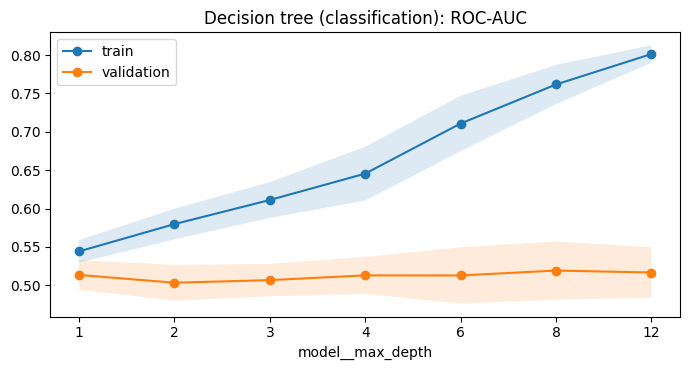

In [111]:
depths = [1, 2, 3, 4, 6, 8, 12]
d_clf = plot_curve(clf, y_classification, "model__max_depth", depths, "roc_auc", "Decision tree (classification): ROC-AUC", "dt_depth_clf.png")

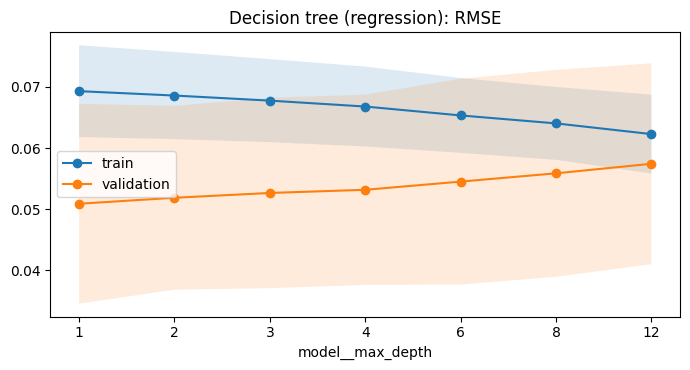

,value,train,validation
0,1,0.544,0.513
1,2,0.580,0.503
2,3,0.611,0.507
3,4,0.645,0.513
4,6,0.711,0.513
5,8,0.762,0.519
6,12,0.801,0.517


In [112]:
d_reg = plot_curve(reg, y_regression, "model__max_depth", depths, "neg_root_mean_squared_error", "Decision tree (regression): RMSE", "dt_depth_reg.png", flip=True)
d_clf.round(3)

Training score keeps climbing with depth while validation stays flat or drops: the tree memorises noise.

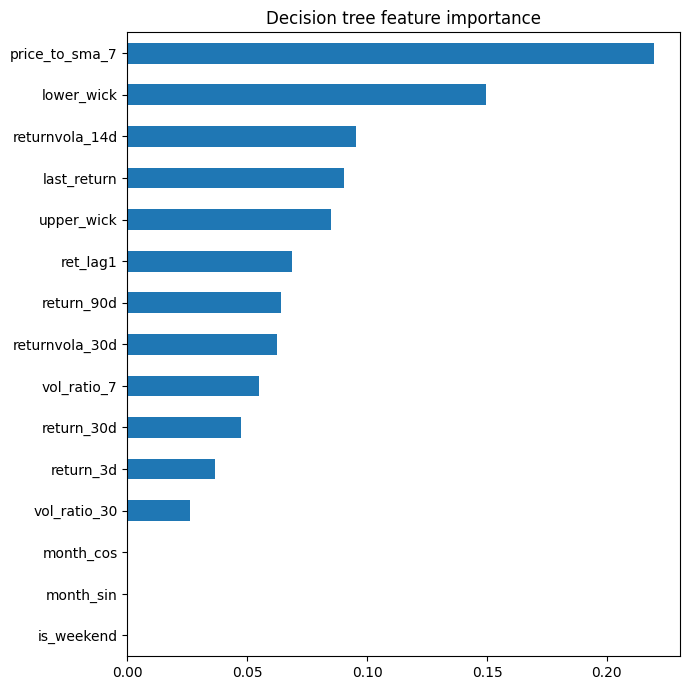

In [115]:
clf.fit(X_train, y_classification)
imp = pd.Series(clf.named_steps["model"].feature_importances_, index=X_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 7)); imp.tail(15).plot.barh(ax=ax); ax.set_title("Decision tree feature importance")
plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/dt_importance.png", dpi=130); plt.show()

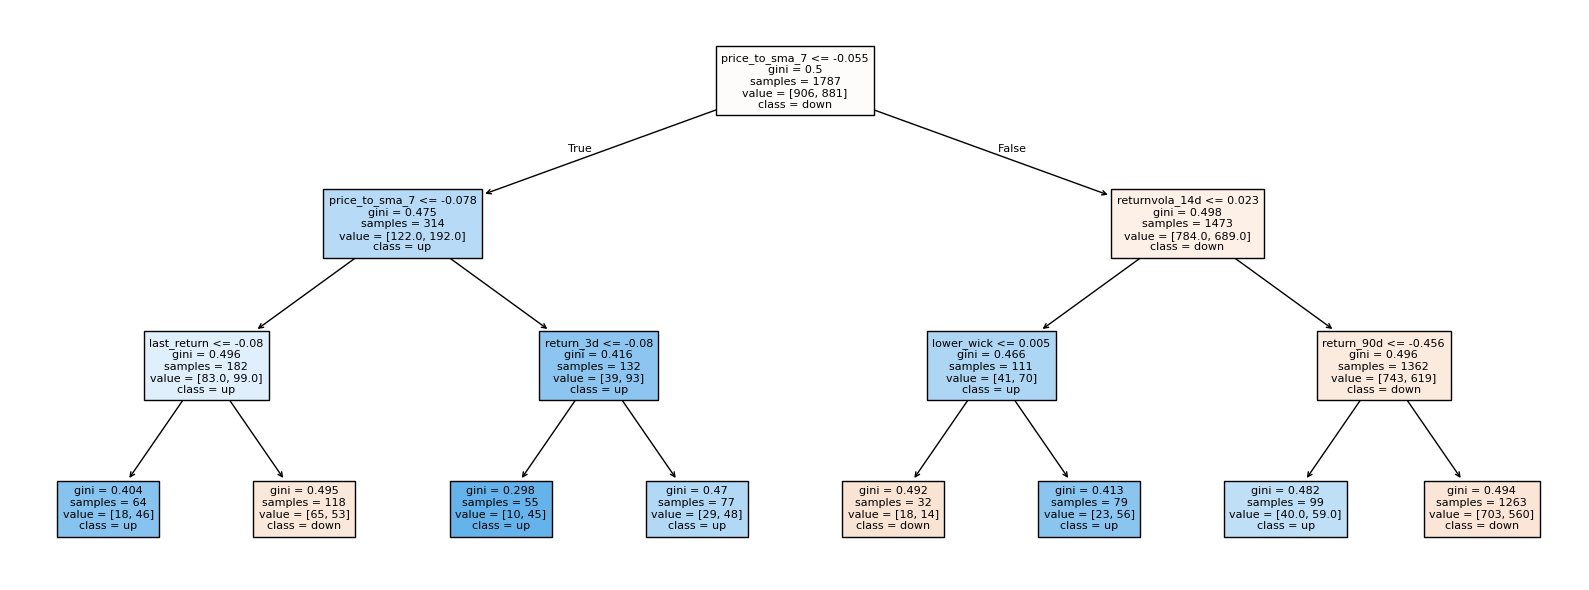

In [120]:
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=42).fit(X_train, y_classification),
          feature_names=X_train.columns, class_names=["down", "up"], filled=True, fontsize=8, ax=ax)
plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/dt_tree.png", dpi=130); plt.show()

In [121]:
rows = [{"model": "Decision Tree", **r_reg}, {"model": "Decision Tree", **r_clf}]
res = pd.DataFrame(rows)

In [123]:
res.to_csv("../../03.results/outputs/model_results_decision_tree.csv", index=False)
res.round(4)

,model,task,rmse,rmse_std,mae,mae_std,r2,r2_std,accuracy,accuracy_std,f1,f1_std,roc_auc,roc_auc_std
0,Decision Tree,regression,0.0532,0.0156,0.0392,0.0113,-0.1768,0.0934,NaN,NaN,NaN,NaN,NaN,NaN
1,Decision Tree,classification,NaN,NaN,NaN,NaN,NaN,NaN,0.5084,0.0322,0.4851,0.0788,0.5129,0.024
